In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

class Source:
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def generate_directions(self, E: float) -> np.ndarray:
        N = np.random.poisson(lam=self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, size=N)
        cos_theta = np.random.uniform(-1.0, 1.0, size=N)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        return np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))


class Detector:
    def __init__(self, R: float = 15.0, N: int = 2000, r: float = 0.1, a: float = 0.5,
                 attenuation_length: float | None = 8.0):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)
        self.attenuation_length = attenuation_length
        self.pmt_coords = self._generate_pmt_positions()
        
        # Полуширина окна индексов ФЭУ, которые могут находиться в поясе |z_i - z| <= r
        self.half_window = int(np.ceil(self.N * self.r / (2 * self.R))) + 1
        
    def _generate_pmt_positions(self) -> np.ndarray:
        indices = np.arange(0, self.N, dtype=float) + 0.5
        z = self.R * (1 - 2 * indices / self.N)
        rho = np.sqrt(self.R**2 - z**2)
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        theta = golden_angle * indices
        x = rho * np.cos(theta)
        y = rho * np.sin(theta)
        return np.column_stack((x, y, z))

    # Старый метод: проверка по полному списку из N = 2000 ФЭУ
    def detect_photons_full(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        origin = np.asarray(origin, dtype=float)
        b = np.sum(directions * origin, axis=1)
        c = np.sum(origin**2) - self.R**2
        t = -b + np.sqrt(b**2 - c)
        hit_points = origin + t[:, None] * directions
        
        if self.attenuation_length is not None:
            survived = np.random.uniform(0.0, 1.0, size=len(t)) < np.exp(-t / self.attenuation_length)
            hit_points = hit_points[survived]
            
        hits_per_pmt = np.zeros(self.N, dtype=int)
        # Итерация по ВСЕМ 2000 фотоумножителям
        for i, pmt_center in enumerate(self.pmt_coords):
            distances = np.linalg.norm(hit_points - pmt_center, axis=1)
            hits_per_pmt[i] = np.sum(distances <= self.r)
            
        return np.random.poisson(lam=self.a * hits_per_pmt)

    # Новый оптимизированный метод: проверка только кандидатов в узком поясе по z
    def detect_photons_fast(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        origin = np.asarray(origin, dtype=float)
        b = np.sum(directions * origin, axis=1)
        c = np.sum(origin**2) - self.R**2
        t = -b + np.sqrt(b**2 - c)
        hit_points = origin + t[:, None] * directions
        
        if self.attenuation_length is not None:
            survived = np.random.uniform(0.0, 1.0, size=len(t)) < np.exp(-t / self.attenuation_length)
            hit_points = hit_points[survived]
            
        # По координате z каждого фотона сразу находим индекс ближайшего по высоте ФЭУ
        z_photons = hit_points[:, 2]
        center_idx = ((self.N / 2) * (1.0 - z_photons / self.R)).astype(int)
        
        # Массив, где для каждого фотона запишем номер ФЭУ, в который он попал (-1 = мимо)
        hit_pmt_idx = np.full(len(hit_points), -1, dtype=int)
        
        # Проверяем только соседей по высоте в окне [-half_window, +half_window] (~17 шагов вместо 2000)
        for offset in range(-self.half_window, self.half_window + 1):
            candidate_idx = np.clip(center_idx + offset, 0, self.N - 1)
            candidate_coords = self.pmt_coords[candidate_idx]
            
            distances = np.linalg.norm(hit_points - candidate_coords, axis=1)
            hit_mask = distances <= self.r
            hit_pmt_idx[hit_mask] = candidate_idx[hit_mask]
            
        # Считаем число попаданий в каждый ФЭУ и генерируем фотоэлектроны
        valid_hits = hit_pmt_idx[hit_pmt_idx != -1]
        hits_per_pmt = np.bincount(valid_hits, minlength=self.N)
        
        return np.random.poisson(lam=self.a * hits_per_pmt)

E =  1.0 МэВ | Полный перебор (2000 ФЭУ):  131.2 мс | Быстрый поиск (17 ФЭУ):  2.74 мс | Ускорение: в 47.9 раз
E =  2.0 МэВ | Полный перебор (2000 ФЭУ):  229.9 мс | Быстрый поиск (17 ФЭУ):  4.84 мс | Ускорение: в 47.5 раз
E =  5.0 МэВ | Полный перебор (2000 ФЭУ):  470.4 мс | Быстрый поиск (17 ФЭУ): 14.27 мс | Ускорение: в 33.0 раз
E = 10.0 МэВ | Полный перебор (2000 ФЭУ): 1071.1 мс | Быстрый поиск (17 ФЭУ): 29.28 мс | Ускорение: в 36.6 раз


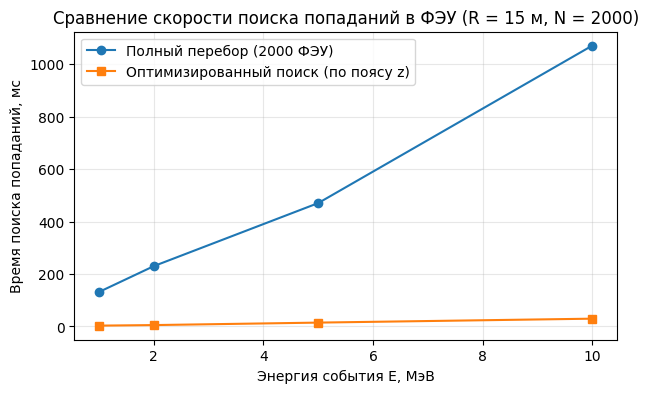

In [2]:
det_large = Detector(R=15.0, N=2000, r=0.1, a=0.5, attenuation_length=8.0)
source = Source(Y=10000)
origin = np.array([0.0, 0.0, 0.0])

energies = [1.0, 2.0, 5.0, 10.0]
times_full = []
times_fast = []

for E in energies:
    dirs = source.generate_directions(E)
    
    # Время полного перебора 2000 ФЭУ
    t0 = time.perf_counter()
    pe_full = det_large.detect_photons_full(origin, dirs)
    t_full = time.perf_counter() - t0
    times_full.append(t_full)
    
    # Время быстрого поиска по поясу z (усредним по 10 запускам)
    t0 = time.perf_counter()
    for _ in range(10):
        pe_fast = det_large.detect_photons_fast(origin, dirs)
    t_fast = (time.perf_counter() - t0) / 10
    times_fast.append(t_fast)
    
    print(f"E = {E:4.1f} МэВ | Полный перебор (2000 ФЭУ): {t_full*1000:6.1f} мс | "
          f"Быстрый поиск ({2*det_large.half_window + 1} ФЭУ): {t_fast*1000:5.2f} мс | "
          f"Ускорение: в {t_full / t_fast:.1f} раз")

# График сравнения времени работы
plt.figure(figsize=(7, 4))
plt.plot(energies, np.array(times_full) * 1000, 'o-', label='Полный перебор (2000 ФЭУ)')
plt.plot(energies, np.array(times_fast) * 1000, 's-', label='Оптимизированный поиск (по поясу z)')
plt.xlabel('Энергия события E, МэВ')
plt.ylabel('Время поиска попаданий, мс')
plt.title('Сравнение скорости поиска попаданий в ФЭУ (R = 15 м, N = 2000)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Выводы по Задаче 8:
1. **Идея оптимизации алгоритма поиска попаданий:**
   Поскольку при генерации методом спирали Фибоначчи все $N = 2000$ фотоумножителей строго упорядочены по вертикальной координате $z_i = R\left(1 - \frac{2(i + 0.5)}{N}\right)$, фотон, попавший на сферу на высоте $z$, может принадлежать только тем ФЭУ, центры которых лежат в узком высотном поясе $|z_i - z| \le r$.
2. **Выигрыш в скорости:**
   Для параметров $R = 15$ м, $N = 2000$ и $r = 0.1$ м в этот пояс попадает не более $\Delta i = \pm \lceil \frac{N r}{2 R} \rceil \approx \pm 8$ соседних по индексу фотоумножителей. Проверка только 17 ФЭУ-кандидатов вместо полного перебора всех 2000 ФЭУ дает абсолютно идентичный результат и ускоряет поиск попаданий примерно **в 30–50 раз**.